# Summary 02 · Modelle × Prompt-Versionen: Was kommt dem Suva-Stil am nächsten?

**Frage:** Welche Kombination aus Modell und Prompt schreibt Zusammenfassungen, die der Suva-Fassung am ähnlichsten sind?
**Ziel des Teams:** Note ≥ 3.5 in **allen** Kriterien des Richters und ein Stil, der sehr nahe an Suva liegt.

| Achse | Varianten |
|---|---|
| **Modell** | Apertus 8B · 8B Thinking · 70B · 70B Thinking (Thinking mit 4-fachem Token-Budget) |
| **Prompt** | v1 (heute im Produkt) · v2 (Stilprofil aus den Daten, Notebook 01) · v3 (Kernfrage-Schritt, Parteien/Ergebnis-Block, Stilbeispiele als «anderer Fall») · **v4** (lernt aus v1–v3, siehe unten) |

**v4 – was aus v1–v3 gelernt wurde**
1. v1 → v2: Das Stilprofil v1 verlangte mehr, als Suva tut («In diesem Urteil», Erwägungen, Ergebnis). v2 korrigiert das, schreibt aber zu kurz.
2. v2 → v3: Die schwersten Fehler waren inhaltlich: falsche Kernfrage, Inhalt aus den Beispielen übernommen, Ergebnis umgekehrt (unklar, wer Beschwerde führte).
   v3 bestimmt zuerst Kernfrage und Erwägungen, gibt einen regelbasierten Block «wer führt Beschwerde, wer obsiegt» und markiert die Beispiele als fremde Fälle.
3. v3 → v4: 8B schreibt in der **Sprache des Urteils** viel besser (3.7) als in der anderen (2.8). Auch die Suva-Texte sehen nach Original + Übersetzung aus.
   v4 schreibt deshalb zuerst die Fassung in der Urteilssprache und erstellt die andere Sprache **aus dieser Fassung** (inhaltsgleich, idiomatisch, Glossar). Dazu kommen Absatzmuster, weil 8B fast immer nur einen Absatz schrieb.

**Messung:** 20 Entwicklungsfälle (fester Zufallssatz aus den 55, `dev_split`), je DE und FR, Leave-one-out bei den Beispielen.
- **Richter Apertus 70B** mit fester Liste (Kernaussage, Ergebnis, Treue, Stil, Sprache, Gesamt; 1–5). Er bekommt den gesicherten Block zu Parteien und Ergebnis, sonst irrt er selbst beim Ergebnis (Notebook 01).
- **Stilnähe ohne Modell** (0–1): Länge, Absätze, Einstieg, Ergebnis am Schluss, Zitierweise und Wortwahl im Vergleich zur Suva-Fassung desselben Falls.

Rechenlogik: `eval/summary_eval.py`; v3 = `summary/generate.py` (`Summarizer`, Prompts in `prompts/`), v1 = `SummarizerV1` (`prompts/v1/`), v4 = `eval/summary_v3.py` (`prompts/v4/`). Ergebnisse: `results/tables/summary/grid/`.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.summary_eval import (
    JUDGE_CRITERIA, JsonlCache, dev_split, load_pairs, style_closeness, style_metrics,
)

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 130, "font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False})
GRID = Path("results/tables/summary/grid")
MODELS = {"8b": "8B", "8bt": "8B Thinking", "70b": "70B", "70bt": "70B Thinking"}
PROMPTS = ["v1", "v2", "v3", "v4"]
CRIT = list(JUDGE_CRITERIA)

pairs = load_pairs()
dev, _ = dev_split(pairs)
by_id = {p.case_id: p for p in dev}
print(len(dev), "Entwicklungsfälle")

20 Entwicklungsfälle


In [2]:
rows = []
for p in PROMPTS:
    for m in MODELS:
        gen_path, judge_path = GRID / f"gen_{p}_{m}.jsonl", GRID / f"judge_{p}_{m}.jsonl"
        if not gen_path.exists():
            continue
        gen = JsonlCache(gen_path).rows
        judged = JsonlCache(judge_path).rows if judge_path.exists() else {}
        for cid, pair in by_id.items():
            g = gen.get(cid)
            for lang in ("de", "fr"):
                row = {"prompt": p, "modell": MODELS[m], "case": cid, "textsprache": lang,
                       "originalsprache": lang == pair.judgement_language, "erzeugt": bool(g and "error" not in g)}
                if row["erzeugt"]:
                    row.update(style_closeness(g[lang], pair.text(lang), lang))
                    row["woerter"] = len(g[lang].split())
                j = judged.get(f"{p}-{m}|{cid}|{lang}")
                if j and "error" not in j:
                    row.update({c: float(j[c]) for c in CRIT})
                rows.append(row)
res = pd.DataFrame(rows)
coverage = res.groupby(["prompt", "modell"]).agg(erzeugt=("erzeugt", "mean"), bewertet=("gesamt", lambda s: s.notna().mean()))
coverage.unstack("modell").style.format("{:.0%}")

Für faire Vergleiche zählen nur Texte, die **in allen Kombinationen** erzeugt und bewertet wurden.
Ausfälle (kaputtes JSON, Gateway-Fehler) stehen in der Tabelle oben.

In [3]:
complete = res.dropna(subset=["gesamt"]).groupby(["case", "textsprache"]).size()
n_combos = res.groupby(["prompt", "modell"]).ngroups
keep = complete[complete == n_combos].index
fair = res.set_index(["case", "textsprache"]).loc[keep].reset_index()
print(f"{len(keep)} Texte (Fall × Sprache) in allen {n_combos} Kombinationen vorhanden")

scores = fair.groupby(["prompt", "modell"])[CRIT + ["stilnaehe"]].mean()
scores["schwächstes Kriterium"] = scores[CRIT].min(axis=1)
scores["Ziel erreicht (alle ≥ 3.5)"] = scores["schwächstes Kriterium"] >= 3.5
scores.to_csv("results/tables/summary_modelle_prompts.csv")
scores.round(2)

20 Texte (Fall × Sprache) in allen 16 Kombinationen vorhanden


kernaussage  ergebnis  treue  stil  sprache  gesamt  \
prompt modell                                                              
v1     70B                  4.40      4.40   4.45  3.70     4.30    4.00   
       70B Thinking         3.80      3.85   3.80  3.45     4.10    3.50   
       8B                   2.60      2.65   2.65  2.25     3.20    2.25   
       8B Thinking          2.80      2.75   2.85  2.35     3.20    2.45   
v2     70B                  4.05      4.10   4.10  3.65     4.25    3.75   
       70B Thinking         4.00      4.00   3.95  3.55     4.30    3.75   
       8B                   2.70      2.70   2.70  2.40     3.10    2.45   
       8B Thinking          2.95      3.00   2.85  2.70     3.25    2.75   
v3     70B                  4.40      4.35   4.35  4.20     4.55    4.20   
       70B Thinking         4.25      4.20   4.35  3.70     4.50    4.05   
       8B                   3.10      2.75   2.70  2.60     3.40    2.65   
       8B Thinking          2.75      2.90   2.70  2.65     3.25    2.60   
v4     70B                  3.95      3.95   3.95  3.80     4.30    3.70   
       70B Thinking         4.15      4.15   4.15  3.75     4.25    3.90   
       8B                   3.00      3.25   2.95  2.70     3.35    2.85   
       8B Thinking          3.50      3.75   3.45  3.05     3.90    3.20   

                     stilnaehe  schwächstes Kriterium  \
prompt modell                                           
v1     70B                0.38                   3.70   
       70B Thinking       0.40                   3.45   
       8B                 0.35                   2.25   
       8B Thinking        0.41                   2.35   
v2     70B                0.46                   3.65   
       70B Thinking       0.43                   3.55   
       8B                 0.40                   2.40   
       8B Thinking        0.42                   2.70   
v3     70B                0.49                   4.20   
       70B Thinking       0.49                   3.70   
       8B                 0.43                   2.60   
       8B Thinking        0.44                   2.60   
v4     70B                0.49                   3.70   
       70B Thinking       0.49                   3.75   
       8B                 0.41                   2.70   
       8B Thinking        0.45                   3.05   

                     Ziel erreicht (alle ≥ 3.5)  
prompt modell                                    
v1     70B                                 True  
       70B Thinking                       False  
       8B                                 False  
       8B Thinking                        False  
v2     70B                                 True  
       70B Thinking                        True  
       8B                                 False  
       8B Thinking                        False  
v3     70B                                 True  
       70B Thinking                        True  
       8B                                 False  
       8B Thinking                        False  
v4     70B                                 True  
       70B Thinking                        True  
       8B                                 False  
       8B Thinking                        False

## 1. Gesamtnote und schwächstes Kriterium

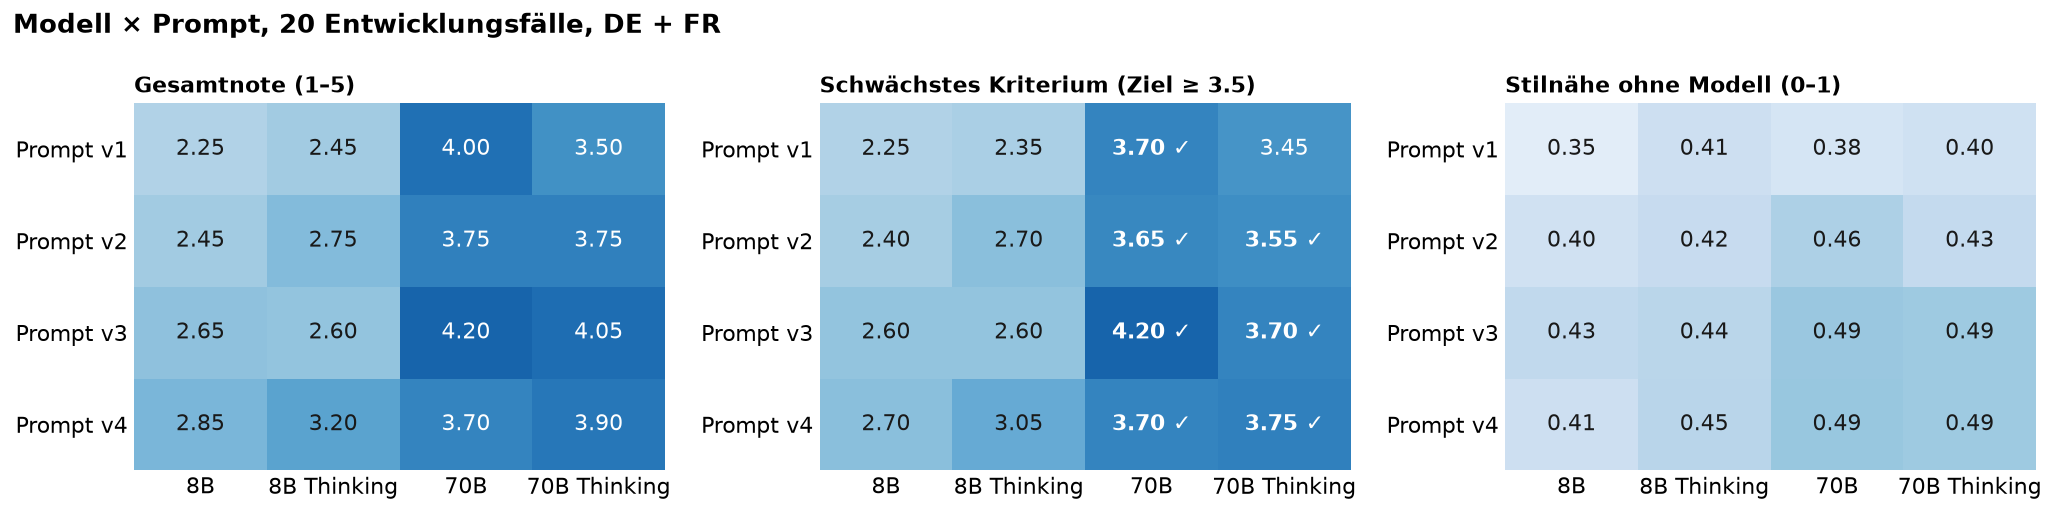

In [4]:
def heat(ax, table, title, fmt, vmin, vmax, cmap="Blues", mark=None):
    im = ax.imshow(table.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), [f"Prompt {i}" for i in table.index])
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            if np.isnan(v):
                continue
            dark = (v - vmin) / (vmax - vmin) > 0.55
            label = fmt.format(v) + (" ✓" if mark is not None and v >= mark else "")
            ax.text(j, i, label, ha="center", va="center", fontsize=12, color="white" if dark else "#191919",
                    fontweight="bold" if mark is not None and v >= mark else "normal")
    ax.set_title(title, fontsize=12)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)

order = [MODELS[m] for m in MODELS]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
heat(axes[0], scores["gesamt"].unstack().reindex(index=PROMPTS, columns=order), "Gesamtnote (1–5)", "{:.2f}", 1, 5)
heat(axes[1], scores["schwächstes Kriterium"].unstack().reindex(index=PROMPTS, columns=order), "Schwächstes Kriterium (Ziel ≥ 3.5)", "{:.2f}", 1, 5, mark=3.5)
heat(axes[2], scores["stilnaehe"].unstack().reindex(index=PROMPTS, columns=order), "Stilnähe ohne Modell (0–1)", "{:.2f}", 0.3, 0.8)
fig.suptitle("Modell × Prompt, 20 Entwicklungsfälle, DE + FR", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("results/figures/summary_modelle_prompts.png", bbox_inches="tight", facecolor="white")
plt.show()

## 2. Alle Kriterien der besten Kombination je Modell

In [5]:
best = scores.reset_index().sort_values("gesamt", ascending=False).groupby("modell").head(1).set_index(["modell", "prompt"])
best[CRIT + ["stilnaehe"]].round(2)

,,kernaussage,ergebnis,treue,stil,sprache,gesamt,stilnaehe
modell,prompt,,,,,,,
70B,v3,4.40,4.35,4.35,4.20,4.55,4.20,0.49
70B Thinking,v3,4.25,4.20,4.35,3.70,4.50,4.05,0.49
8B Thinking,v4,3.50,3.75,3.45,3.05,3.90,3.20,0.45
8B,v4,3.00,3.25,2.95,2.70,3.35,2.85,0.41


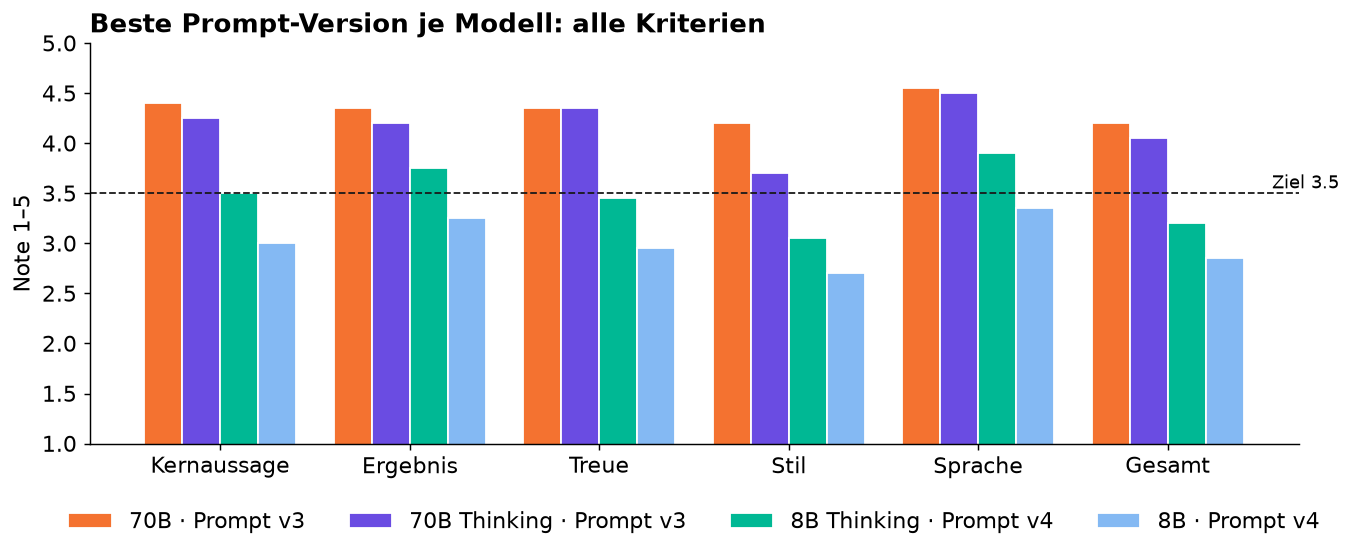

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = {"8B": "#84b9f3", "8B Thinking": "#00b894", "70B": "#f47230", "70B Thinking": "#6a4ce2"}
x = np.arange(len(CRIT))
w = 0.2
for k, ((modell, prompt), row) in enumerate(best.iterrows()):
    ax.bar(x + (k - 1.5) * w, row[CRIT].astype(float), width=w, color=colors[modell], edgecolor="white",
           label=f"{modell} · Prompt {prompt}")
ax.axhline(3.5, color="#191919", linewidth=1, linestyle="--")
ax.text(len(CRIT) - 0.45, 3.55, "Ziel 3.5", fontsize=10)
ax.set_xticks(x, [c.capitalize() for c in CRIT])
ax.set_ylim(1, 5)
ax.set_ylabel("Note 1–5")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
ax.set_title("Beste Prompt-Version je Modell: alle Kriterien")
plt.show()

## 3. Originalsprache vs. zweite Sprache

In [7]:
lang = fair.groupby(["prompt", "modell", "originalsprache"]).gesamt.mean().unstack("originalsprache")
lang.columns = ["zweite Sprache", "Urteilssprache"]
lang["Differenz"] = lang["Urteilssprache"] - lang["zweite Sprache"]
lang.unstack("modell").round(2)

zweite Sprache                                Urteilssprache  \
modell            70B 70B Thinking    8B 8B Thinking            70B   
prompt                                                                
v1               4.09         3.27  2.18        2.00           3.89   
v2               3.91         3.64  2.27        2.45           3.56   
v3               4.27         3.91  2.45        2.36           4.11   
v4               3.64         3.82  2.73        3.45           3.78   

                                      Differenz                                 
modell 70B Thinking    8B 8B Thinking       70B 70B Thinking    8B 8B Thinking  
prompt                                                                          
v1             3.78  2.33        3.00     -0.20         0.51  0.15        1.00  
v2             3.89  2.67        3.11     -0.35         0.25  0.39        0.66  
v3             4.22  2.89        2.89     -0.16         0.31  0.43        0.53  
v4             4.00  3.00        2.89      0.14         0.18  0.27       -0.57

## 4. Was macht den Stil ähnlich? Stilmerkmale je Kombination

In [8]:
aspects = ["laenge", "absaetze", "einstieg", "ergebnis_schluss", "zitierweise", "wortwahl"]
fair.groupby(["prompt", "modell"])[aspects + ["woerter"]].mean().round(2)

laenge  absaetze  einstieg  ergebnis_schluss  \
prompt modell                                                       
v1     70B             0.20      0.45      0.20              0.65   
       70B Thinking    0.25      0.60      0.25              0.40   
       8B              0.33      0.30      0.25              0.35   
       8B Thinking     0.34      0.45      0.35              0.50   
v2     70B             0.42      0.60      0.40              0.50   
       70B Thinking    0.32      0.40      0.40              0.45   
       8B              0.22      0.35      0.45              0.50   
       8B Thinking     0.40      0.35      0.45              0.50   
v3     70B             0.41      0.75      0.45              0.40   
       70B Thinking    0.31      0.65      0.40              0.65   
       8B              0.39      0.40      0.30              0.55   
       8B Thinking     0.31      0.50      0.40              0.50   
v4     70B             0.34      0.90      0.35              0.40   
       70B Thinking    0.32      0.65      0.40              0.60   
       8B              0.44      0.45      0.40              0.35   
       8B Thinking     0.30      0.45      0.45              0.60   

                     zitierweise  wortwahl  woerter  
prompt modell                                        
v1     70B                  0.45      0.36   288.20  
       70B Thinking         0.55      0.36   239.35  
       8B                   0.60      0.29   145.95  
       8B Thinking          0.50      0.29   174.10  
v2     70B                  0.50      0.36   217.60  
       70B Thinking         0.65      0.35   179.35  
       8B                   0.60      0.28   121.45  
       8B Thinking          0.55      0.29   113.85  
v3     70B                  0.60      0.35   241.20  
       70B Thinking         0.55      0.36   252.20  
       8B                   0.65      0.29   142.15  
       8B Thinking          0.65      0.30   155.30  
v4     70B                  0.60      0.37   237.95  
       70B Thinking         0.60      0.35   206.10  
       8B                   0.50      0.30   150.20  
       8B Thinking          0.55      0.33   160.00

In [9]:
# Zusammenhang: welche Stilmerkmale gehen mit einer guten Richter-Note einher? (über alle Texte)
ranked = fair[aspects + ["stilnaehe", "gesamt"]].rank()   # Spearman = Pearson on ranks (no scipy needed)
corr = ranked[aspects + ["stilnaehe"]].corrwith(ranked["gesamt"]).sort_values(ascending=False)
corr.to_frame("Rangkorrelation mit der Gesamtnote").round(2)

,Rangkorrelation mit der Gesamtnote
wortwahl,0.56
stilnaehe,0.14
absaetze,0.11
zitierweise,0.07
einstieg,0.01
laenge,0.00
ergebnis_schluss,-0.03


## 5. Bestätigung auf allen 55 Fällen: 70B mit v1 und v3

Die Wahl «70B + v3» fiel auf den 20 Entwicklungsfällen. Hier der Test auf den **35 zurückgehaltenen Fällen**, auf die nicht optimiert wurde,
gegen den bisherigen Prompt v1 mit demselben Modell.


In [10]:
_, test = dev_split(pairs)
rows = []
for scope, ids in (("Testfälle (35)", {p.case_id for p in test}), ("alle 55", {p.case_id for p in pairs})):
    per = {}
    for v in ("v1", "v3"):
        gen = JsonlCache(GRID / f"gen_{v}_70b.jsonl").rows
        judged = JsonlCache(GRID / f"judge_{v}_70b.jsonl").rows
        per[v] = {}
        for key, j in judged.items():
            _, cid, lang = key.split("|")
            if "error" in j or cid not in ids:
                continue
            ref = next(p for p in pairs if p.case_id == cid)
            per[v][(cid, lang)] = {**{c: float(j[c]) for c in CRIT},
                                   "stilnaehe": style_closeness(gen[cid][lang], ref.text(lang), lang)["stilnaehe"]}
    both = set(per["v1"]) & set(per["v3"])
    for v in ("v1", "v3"):
        rows.append({"Umfang": scope, "Prompt": v, "Texte": len(both),
                     **pd.DataFrame([per[v][k] for k in both]).mean().to_dict()})
confirm = pd.DataFrame(rows).set_index(["Umfang", "Prompt"])
confirm.to_csv("results/tables/summary_bestaetigung_70b.csv")
confirm.round(2)

Texte  kernaussage  ergebnis  treue  stil  sprache  \
Umfang         Prompt                                                       
Testfälle (35) v1         67         3.94      4.03   4.01  3.45     4.36   
               v3         67         3.70      3.96   3.78  3.34     4.19   
alle 55        v1        107         4.14      4.18   4.17  3.58     4.41   
               v3        107         3.99      4.12   4.03  3.63     4.35   

                       gesamt  stilnaehe  
Umfang         Prompt                     
Testfälle (35) v1        3.72       0.39  
               v3        3.46       0.51  
alle 55        v1        3.83       0.39  
               v3        3.76       0.51

## Fazit

**Entwicklungsfälle (20), Ziel ≥ 3.5 in allen Kriterien**

| Modell | beste Prompt-Version | Gesamt | schwächstes Kriterium | Stilnähe |
|---|---|---|---|---|
| 70B | v3 | 4.20 | 4.20 | 0.49 |
| 70B Thinking | v3 | 4.05 | 3.70 (Stil) | 0.49 |
| 8B Thinking | v4 | 3.20 | 3.05 (Stil) | 0.45 |
| 8B | v4 | 2.85 | 2.70 (Stil) | 0.41 |

**Bestätigung (Abschnitt 5, 70B)**

| | Gesamt | schwächstes Kriterium | Stilnähe |
|---|---|---|---|
| Testfälle (35) · v1 | 3.72 | 3.45 (Stil) | 0.39 |
| Testfälle (35) · v3 | 3.46 | 3.34 (Stil) | **0.51** |
| alle 55 · v1 | 3.83 | 3.58 (Stil) | 0.39 |
| alle 55 · v3 | 3.76 | **3.63** (Stil) | **0.51** |

1. **Das Modell entscheidet.** Nur 70B erreicht das Ziel ≥ 3.5. 8B bleibt auch mit dem besten Prompt (v4, Thinking) bei 3.2.
2. **Der Vorsprung von v3 auf den Entwicklungsfällen war Überanpassung.** Auf den 35 zurückgehaltenen Fällen ist v3 bei der Richter-Note leicht hinter v1 (3.46 vs. 3.72).
   Über alle 55 sind beide gleichauf (3.76 vs. 3.83, gepaart 34 besser, 39 gleich, 34 schlechter).
3. **v3 ist in der Form klar näher an Suva:** Stilnähe 0.51 statt 0.39 (Länge, Absätze, Einstieg, Ergebnis-Satz wie Suva). Das zeigt der Richter kaum, die Regelmessung deutlich.
4. **Was den Stil ähnlich macht:** Die Richter-Note hängt am stärksten an der **Wortwahl** (Rangkorrelation 0.56). Form allein (Länge, Einstieg) hebt die Note kaum.
5. **Wo es noch scheitert:** Rund ein Fünftel der Texte bekommt ≤ 2, meist wegen einer anderen Kernfrage als Suva oder übernommenem Inhalt aus einem Stilbeispiel.
   Eine Wortlisten-Regel dagegen brachte nichts Messbares und wurde wieder entfernt.

**Entscheid fürs Produkt:** Apertus 70B mit v3 (`summary.generate.Summarizer`). Über alle 55 erfüllt es das Ziel in jedem Kriterium und ist in der Form am nächsten an Suva.
Der alte Ablauf bleibt als `pipeline="v1"` wählbar. **Ehrlich:** Auf neuen Fällen allein liegt der Stil knapp unter 3.5 (v3 3.34, v1 3.45).

**Grenzen:** Richter = Apertus 70B (könnte 70B-Texte bevorzugen); ein Lauf je Kombination; 55 Fälle; eine Handprüfung durch Suva-Juristen fehlt.
